# Capstone — Which content pages should an editor review first?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Thomasayanfeoluwa/flyrank-data-pipeline/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

**The problem.** A content team looks after thousands of articles but has only a few hours a week to review them. Some pages quietly lose search impressions, and the loss is often noticed late. Which pages should an editor look at first?

**The question.** Can a simple, readable model rank pages so that the top of the list holds more pages that lost 30% or more of their search impressions than picking pages at random does, when it is tested on clients it has never seen?

**The decision it supports.** A human editor decides whether to refresh, expand, leave alone or monitor a page. The ranking is a screening list for that decision; nothing is changed automatically.

**Where it comes from.** The same problem sits behind a recommendation in FlyRank's March 2026 data report, *The State of AI-Driven SEO*: refresh strong content before it decays. That recommendation needs a way to find the pages that are decaying. This paper tests one such way on a public-safe slice of real search data and states how far the evidence goes.

**What this paper does not claim.** It does not claim to predict Google's ranking system, to forecast future decay, or to show that refreshing a page helps. It also does not test the report's refresh findings, which are observational cohort comparisons. Every result is observed on one snapshot and is offered as directional, decision-support evidence.

## 2. Data

**Release.** The FlyRank ML Internship dataset: an anonymized slice of production search data (Google Search Console and GA4 aggregates). It holds 30,000 content pages from several clients, with 44 columns per page: 90-day totals, two 30-day windows (the last 30 days and the 30 days before), page attributes such as length and age, and keyword fields. It is a single snapshot. Identifiers are hashed; the release contains no client names, domains, URLs, titles or keywords, and no raw export is stored in this repository. The FlyRank report analyzes a much larger portfolio (341,701 content pieces across 57 brands); this paper uses only the 30,000-page starter release, so its counts are not comparable with the report's.

**Label (proxy).** A page is labeled *decaying* if its impressions in the last 30 days fell by 30% or more compared with the 30 days before. The 30% cutoff is an assumption and was not tuned. It is stricter than the FlyRank report's "down" trend, which starts at a 10% decline, so the two decay counts are not the same measure.

**What is excluded, and why.**
1. Pages with no impressions in the prior 30 days: the change is undefined, so they cannot be judged.
2. Pages with fewer than 100 impressions in 90 days: for these the label is often forced by the data. A page with a single impression in 90 days, if it is labeled at all, must have lost it in the last 30 days. An early run without this filter let a model reach a precision of 1.00 at the top of the list by finding such pages, so the filter was added after that check, not before.
3. Columns that define or sit inside the label: the trend columns and every 30-day window column.
4. Identifiers, used only to group pages by client when splitting the data.

The table below shows how many pages remain at each step.

In [1]:
!test -d repo || git clone --depth 1 https://github.com/flyrank-bih/flyrank-ml-internship-starter.git repo
!cp -r repo/data .

Cloning into 'repo'...
remote: Enumerating objects: 94, done.
remote: Counting objects: 100% (94/94), done.
remote: Compressing objects: 100% (77/77), done.
remote: Total 94 (delta 12), reused 29 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (94/94), 1.83 MiB | 3.93 MiB/s, done.
Resolving deltas: 100% (12/12), done.


In [2]:
import numpy as np
import pandas as pd
import sklearn

SEED = 42
MIN_IMPRESSIONS = 100          # review population: enough traffic to judge a decline
DECAY_CUTOFF = -30.0           # percent change in impressions, last 30 days vs prior 30 days

raw = pd.read_csv("data/raw/content_refresh_anonymized.csv")

df = raw[raw["trend_pct"].notna()].reset_index(drop=True)          # needs a prior-30-day baseline
df["is_decayed"] = ((df["trend_direction"] == "down") & (df["trend_pct"] <= DECAY_CUTOFF)).astype(int)
labeled = len(df)
df = df[df["impressions_90d"] >= MIN_IMPRESSIONS].reset_index(drop=True)   # enough traffic to judge

FORBIDDEN = ["trend_direction", "trend_pct", "is_decayed"] + \
            [c for c in df.columns if c.endswith(("_last_30d", "_prev_30d"))]
FEATURES = [c for c in df.columns if c not in FORBIDDEN + ["content_id", "client_id"]]

funnel = pd.DataFrame([
    {"step": "Pages in the starter release",                       "pages": len(raw),
     "clients": raw["client_id"].nunique()},
    {"step": "Have a prior-30-day baseline (labeled)",             "pages": labeled,
     "clients": raw.loc[raw["trend_pct"].notna(), "client_id"].nunique()},
    {"step": "Review population (>= 100 impressions in 90 days)",  "pages": len(df),
     "clients": df["client_id"].nunique()},
])
funnel["share decaying"] = ["", "", f"{df['is_decayed'].mean():.1%}"]
print(funnel.to_string(index=False))

non_features = [c for c in FORBIDDEN if c in raw.columns]     # is_decayed is created here
print(f"\nColumns in the release: {raw.shape[1]} | features used: {len(FEATURES)} | "
      f"not features: {len(non_features)} label/window columns + 2 identifiers")
print(f"Decaying (fell 30% or more): {int(df['is_decayed'].sum()):,} of {len(df):,} pages (base rate {df['is_decayed'].mean():.3f})")
print("\nsklearn", sklearn.__version__, "| pandas", pd.__version__, "| seed", SEED)

                                             step  pages  clients share decaying
                     Pages in the starter release  30000       32               
           Have a prior-30-day baseline (labeled)  26612       31               
Review population (>= 100 impressions in 90 days)  21758       30          51.4%

Columns in the release: 44 | features used: 34 | not features: 8 label/window columns + 2 identifiers
Decaying (fell 30% or more): 11,174 of 21,758 pages (base rate 0.514)

sklearn 1.6.1 | pandas 2.2.3 | seed 42


**Observed**

| Step | Pages | Clients |
|---|---|---|
| Pages in the starter release | 30,000 | 32 |
| Have a prior-30-day baseline (labeled) | 26,612 | 31 |
| Review population (at least 100 impressions in 90 days) | 21,758 | 30 |

- 3,388 pages were left out for having no prior-30-day baseline, and 4,854 labeled pages for having fewer than 100 impressions in 90 days.
- In the review population, 11,174 of 21,758 pages (51.4%) fell by 30% or more. A random ranking would therefore put about 51% decaying pages at the top of the list, and this base rate is shown next to every result in this paper.
- The model uses 34 features. The other 10 columns of the release are 8 label or 30-day window columns and 2 identifiers (34 + 8 + 2 = 44).

## 3. Methodology

**Assumptions.** One snapshot, with no time dimension. The label is a proxy for decay: a fall of 30% or more in impressions, last 30 days versus the prior 30 days; the cutoff is an assumption and was not tuned. K = 500 pages is an assumed editorial capacity per review cycle (the release has no capacity field).

**Features (34).** Six families, all computed from 90-day totals and page attributes: visibility consistency (2 features), volume (9), position and CTR (3), on-page engagement (3), page profile (11: length, age, update date, type, intent) and keyword and source (6). Not used as features: the label columns, every 30-day window column, and the identifiers.

**Baseline.** A hand-written rule with no training: flag a page with 100 to 499 impressions in 90 days that has not been updated for 91 days or more, and rank flagged pages by `min(days since update, 365) / 365 × (500 − impressions) / 400`. It was built from two signal checks on this same data (staleness was a weak signal; higher volume was linked to *less* decay), and its cutoffs were chosen after seeing those tables. That gives the baseline an advantage, so a comparison against it is conservative.

**Models.** Logistic Regression (readable, with one-hot categories and scaled numbers) and Gradient boosting (`HistGradientBoostingClassifier`, handles missing values natively). Settings are fixed in the code (seed 42) and not tuned.

**Validation design.** 5-fold cross-validation grouped by client: every client sits on one side of each split only, so every page is scored by a model that never saw its client. The baseline is scored on the same pages. The main metric is precision@K (the share of the K top-ranked pages that are labeled decaying) printed next to the base rate; AUC is secondary, and intervals come from resampling clients. A time-aware split is not possible with one snapshot.

**Leakage checks.**
1. The label columns and all 30-day window columns are excluded, enforced by assertions in the code.
2. A deliberate leak: add the two label-window columns, watch the score jump, then remove them and keep the honest number.
3. A check that the release has no flag, action or score columns from an existing system.
4. The overlap between the 90-day totals and the label windows, and the population rule, are measured in the next section because they affect how far the results can be read.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

y = df["is_decayed"].values
groups = df["client_id"].values
ids = df["content_id"].values
base_rate = y.mean()

X = df[FEATURES].copy()
NUMERIC = X.select_dtypes(include="number").columns.tolist()
CATEGORICAL = [c for c in FEATURES if c not in NUMERIC]
for c in CATEGORICAL:
    X[c] = X[c].astype("category")
X_lr = X.copy()
for c in CATEGORICAL:
    X_lr[c] = X_lr[c].astype(object)

FAMILIES = {
    "visibility consistency": ["days_with_impressions", "days_with_sessions"],
    "volume": ["impressions_90d", "clicks_90d", "pageviews_90d", "sessions_90d", "users_90d",
               "engaged_sessions_90d", "ai_sessions_90d", "scroll_events_90d", "impression_tier"],
    "position and CTR": ["avg_position", "ctr", "position_tier"],
    "on-page engagement": ["engagement_rate", "scroll_rate", "ai_traffic_pct"],
    "page profile": ["word_count", "char_count", "content_age_days", "days_since_last_update", "age_tier",
                     "age_tier_order", "freshness_tier", "word_count_tier", "char_count_tier",
                     "content_type", "main_intent"],
    "keyword and source": ["search_volume", "competition", "competition_level", "cpc",
                           "provider_used", "model_used"],
}
col_family = {c: f for f, cols in FAMILIES.items() for c in cols}
assert set(FEATURES) == set(col_family), "every feature needs exactly one family"
assert not set(FEATURES) & set(FORBIDDEN), "a label or window column is among the features"

def make_logistic():
    prep = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMERIC),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="missing")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAL)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=1000, random_state=SEED))])

def make_boosting():
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                          categorical_features="from_dtype", random_state=SEED)

def p_at_k(y_true, score, k, tie_ids):
    return y_true[np.lexsort((tie_ids, -score))[:k]].mean()

# Baseline: the hand-written Week-4 rule (no training)
flagged = ((df["impressions_90d"] >= 100) & (df["impressions_90d"] < 500) & (df["days_since_last_update"] >= 91))
baseline_score = np.where(flagged, df["days_since_last_update"].clip(upper=365) / 365
                          * (500 - df["impressions_90d"]) / 400, 0.0)

# Validation design: 5 folds, every client on one side only
folds = list(GroupKFold(n_splits=5).split(df, y, groups))

def grouped_oof(features, make=make_boosting, fold_list=folds):
    oof = np.zeros(len(y))
    for tr, te in fold_list:
        oof[te] = make().fit(features.iloc[tr], y[tr]).predict_proba(features.iloc[te])[:, 1]
    return oof

print("Features by family:", {f: len(c) for f, c in FAMILIES.items()}, "| total", len(FEATURES))
print(f"Baseline rule flags {int(flagged.sum()):,} pages ({flagged.mean():.1%}); the rest score 0")
print(pd.DataFrame([{"fold": i, "test pages": len(te), "test clients": len(set(groups[te])),
                     "test base rate": round(y[te].mean(), 3)} for i, (tr, te) in enumerate(folds, 1)]).to_string(index=False))
print(f"Clients shared between train and test (all folds): {sum(len(set(groups[tr]) & set(groups[te])) for tr, te in folds)}")

Features by family: {'visibility consistency': 2, 'volume': 9, 'position and CTR': 3, 'on-page engagement': 3, 'page profile': 11, 'keyword and source': 6} | total 34
Baseline rule flags 1,531 pages (7.0%); the rest score 0
 fold  test pages  test clients  test base rate
    1        6567             1           0.379
    2        3796             6           0.533
    3        3799             7           0.444
    4        3800             8           0.717
    5        3796             8           0.591
Clients shared between train and test (all folds): 0


In [4]:
LEAK = ["impressions_last_30d", "impressions_prev_30d"]   # the two inputs of trend_pct, i.e. of the label

def summarize(oof):
    return round(roc_auc_score(y, oof), 3), round(p_at_k(y, oof, 500, ids), 3)

auc_honest, p_honest = summarize(grouped_oof(X))
X_leak = X.copy()
for c in LEAK:
    X_leak[c] = df[c].values
auc_leak, p_leak = summarize(grouped_oof(X_leak))
X_leak = X_leak.drop(columns=LEAK)
assert list(X_leak.columns) == list(X.columns)
auc_after, p_after = summarize(grouped_oof(X_leak))

print(f"Base rate: {base_rate:.3f}\n")
print(pd.DataFrame([
    {"gradient boosting features": "34 features (honest)",           "AUC": auc_honest, "P@500": p_honest},
    {"gradient boosting features": "+ the two label-window columns", "AUC": auc_leak,   "P@500": p_leak},
    {"gradient boosting features": "leak removed again",             "AUC": auc_after,  "P@500": p_after},
]).to_string(index=False))

source_columns = pd.read_csv("data/raw/content_refresh_anonymized.csv", nrows=0).columns
print("\nFlag-like columns in the source data:",
      [c for c in source_columns if any(k in c.lower() for k in ["flag", "action", "recommend", "priority", "rule", "reason"])])
share = (df["impressions_last_30d"] + df["impressions_prev_30d"]) / df["impressions_90d"]
print(f"The two label windows hold a median of {share.median():.0%} of impressions_90d")

Base rate: 0.514

    gradient boosting features   AUC  P@500
          34 features (honest) 0.667   0.71
+ the two label-window columns 0.999   1.00
            leak removed again 0.667   0.71

Flag-like columns in the source data: []
The two label windows hold a median of 56% of impressions_90d


**Observed**

- **Features:** 34 in six families (visibility consistency 2, volume 9, position and CTR 3, on-page engagement 3, page profile 11, keyword and source 6). An assertion confirms that none of them is a label or 30-day window column.
- **Baseline:** the rule flags 1,531 pages (7.0% of the review population); all other pages score 0.
- **Validation design:** five folds whose test sides add up to the 21,758 pages (6,567 + 3,796 + 3,799 + 3,800 + 3,796), so each page is tested once, with 0 clients shared between train and test. The folds are uneven: fold 1's test side is a single client with 6,567 pages, and the test base rate ranges from 0.379 to 0.717 across folds, so fold-to-fold spread is reported with the results.
- **Deliberate leak (Gradient boosting, client-grouped, base rate 0.514):** adding the two label-window columns raised AUC from 0.667 to 0.999 and P@500 from 0.710 to 1.00. Removing them returned both to 0.667 and 0.710. The check responds to a leak, so excluding those columns was necessary.
- **Product flags:** the release has no flag, action, score or reason columns, so no output of an existing system is used as an input.
- **Overlap, to be read with the results:** the two label windows hold a median of 56% of each page's 90-day impressions, so the 90-day totals used as features are largely the same weeks the label is built from. This is tested in the results section.

## 4. Results (vs baseline)

Everything below uses the same 21,758 pages and the same five client-grouped folds. The Week-4 rule, Logistic Regression and Gradient boosting are scored on exactly the same test pages, and the base rate (0.514) is printed next to every result, because a high precision can simply reflect a high base rate. Precision@K means the share of the K top-ranked pages that are labeled decaying; lift is precision divided by the base rate.

**4a. Main comparison.** Pooled over all pages (the top K of the whole review population), per fold (with the spread across folds), and with intervals from resampling the 30 clients.

**4b. Before and after the honest split.** The same models and features, scored once with a random split and once with the client-grouped split.

In [5]:
oof = {"Logistic Regression": grouped_oof(X_lr, make_logistic), "Gradient boosting": grouped_oof(X)}
scores = {"Baseline (Week-4 rule)": baseline_score, **oof}

Ks = [10, 50, 100, 500]
pooled = []
for name, s in scores.items():
    row = {"method": name}
    for k in Ks:
        row[f"P@{k}"] = round(p_at_k(y, s, k, ids), 3)
    row["lift@500"] = round(row["P@500"] / base_rate, 2)
    row["AUC"] = round(roc_auc_score(y, s), 3)
    pooled.append(row)
print(f"Base rate: {base_rate:.3f} | pages: {len(y):,}\n")
print("Pooled out-of-fold (top K of all pages):")
print(pd.DataFrame(pooled).to_string(index=False))

# Per fold: top 2% of each test fold, as lift over that fold's own base rate
fold_rows = []
for name, s in scores.items():
    aucs, lifts = [], []
    for tr, te in folds:
        k = max(1, round(0.02 * len(te)))
        aucs.append(roc_auc_score(y[te], s[te]))
        lifts.append(p_at_k(y[te], s[te], k, ids[te]) / y[te].mean())
    fold_rows.append({"method": name, "AUC": f"{np.mean(aucs):.3f} ± {np.std(aucs):.3f}",
                      "lift@top2%": f"{np.mean(lifts):.2f} ± {np.std(lifts):.2f}"})
print("\nPer fold (5 folds, mean ± std):")
print(pd.DataFrame(fold_rows).to_string(index=False))

# Uncertainty: resample the clients 1,000 times
rng = np.random.default_rng(SEED)
client_ids = np.unique(groups)
rows_by_client = {c: np.where(groups == c)[0] for c in client_ids}
lift = {name: [] for name in scores}
for _ in range(1000):
    idx = np.concatenate([rows_by_client[c] for c in rng.choice(client_ids, size=len(client_ids), replace=True)])
    for name, s in scores.items():
        lift[name].append(p_at_k(y[idx], s[idx], 500, ids[idx]) / y[idx].mean())
lift = {name: np.array(v) for name, v in lift.items()}

def interval(a):
    lo, hi = np.percentile(a, [2.5, 97.5])
    return f"{lo:.2f} to {hi:.2f}"

print("\nLift@500, 95% interval from resampling the 30 clients:")
for name, s in scores.items():
    print(f"  {name:24} {p_at_k(y, s, 500, ids) / base_rate:.2f}x  ({interval(lift[name])})")
print("\nPaired differences in lift@500 (same resampled clients):")
for a, b in [("Logistic Regression", "Baseline (Week-4 rule)"), ("Gradient boosting", "Baseline (Week-4 rule)"),
             ("Logistic Regression", "Gradient boosting")]:
    d = lift[a] - lift[b]
    print(f"  {a} minus {b}: median {np.median(d):+.2f}, 95% interval {interval(d)}, first is higher in {np.mean(d > 0):.0%} of resamples")

Base rate: 0.514 | pages: 21,758

Pooled out-of-fold (top K of all pages):
                method  P@10  P@50  P@100  P@500  lift@500   AUC
Baseline (Week-4 rule)   0.5  0.68   0.64  0.618      1.20 0.511
   Logistic Regression   0.7  0.78   0.83  0.794      1.55 0.638
     Gradient boosting   0.5  0.76   0.72  0.710      1.38 0.667

Per fold (5 folds, mean ± std):
                method           AUC  lift@top2%
Baseline (Week-4 rule) 0.512 ± 0.013 1.13 ± 0.11
   Logistic Regression 0.650 ± 0.017 1.59 ± 0.26
     Gradient boosting 0.654 ± 0.026 1.47 ± 0.32

Lift@500, 95% interval from resampling the 30 clients:
  Baseline (Week-4 rule)   1.20x  (0.92 to 1.35)
  Logistic Regression      1.55x  (1.22 to 1.87)
  Gradient boosting        1.38x  (1.04 to 1.74)

Paired differences in lift@500 (same resampled clients):
  Logistic Regression minus Baseline (Week-4 rule): median +0.35, 95% interval 0.00 to 0.75, first is higher in 98% of resamples
  Gradient boosting minus Baseline (Week-4 rul

In [6]:
random_folds = list(KFold(n_splits=5, shuffle=True, random_state=SEED).split(df))
rows = []
for split_name, fold_list in [("Random split (before)", random_folds), ("Grouped by client (after)", folds)]:
    seen = np.mean(np.concatenate([np.isin(groups[te], np.unique(groups[tr])) for tr, te in fold_list]))
    for model_name, make, feats in [("Logistic Regression", make_logistic, X_lr), ("Gradient boosting", make_boosting, X)]:
        s = grouped_oof(feats, make, fold_list)
        rows.append({"split": split_name, "model": model_name, "P@500": round(p_at_k(y, s, 500, ids), 3),
                     "lift@500": round(p_at_k(y, s, 500, ids) / base_rate, 2), "AUC": round(roc_auc_score(y, s), 3),
                     "test pages from clients seen in training": f"{seen:.0%}"})
print(f"Base rate: {base_rate:.3f}\n")
print(pd.DataFrame(rows).to_string(index=False))

Base rate: 0.514

                    split               model  P@500  lift@500   AUC test pages from clients seen in training
    Random split (before) Logistic Regression  0.862      1.68 0.736                                     100%
    Random split (before)   Gradient boosting  0.936      1.82 0.775                                     100%
Grouped by client (after) Logistic Regression  0.794      1.55 0.638                                       0%
Grouped by client (after)   Gradient boosting  0.710      1.38 0.667                                       0%


**Observed**

**4a. Main comparison** (21,758 pages, base rate 0.514, same five client-grouped folds):

| Method | P@10 | P@50 | P@100 | P@500 | Lift@500 | AUC (pooled) | AUC per fold | Lift@top 2%, per fold |
|---|---|---|---|---|---|---|---|---|
| Baseline (Week-4 rule) | 0.50 | 0.68 | 0.64 | 0.618 | 1.20x | 0.511 | 0.512 ± 0.013 | 1.13 ± 0.11 |
| Logistic Regression | 0.70 | 0.78 | 0.83 | 0.794 | 1.55x | 0.638 | 0.650 ± 0.017 | 1.59 ± 0.26 |
| Gradient boosting | 0.50 | 0.76 | 0.72 | 0.710 | 1.38x | 0.667 | 0.654 ± 0.026 | 1.47 ± 0.32 |

Lift@500 with a 95% interval from resampling the 30 clients: baseline 1.20x (0.92 to 1.35), Logistic Regression 1.55x (1.22 to 1.87), Gradient boosting 1.38x (1.04 to 1.74). In paired comparisons on the same resampled clients:
- Logistic Regression minus the baseline: median +0.35, interval 0.00 to 0.75, higher in 98% of resamples.
- Gradient boosting minus the baseline: median +0.21, interval -0.14 to 0.59, higher in 85% of resamples.
- Logistic Regression minus Gradient boosting: median +0.15, interval 0.01 to 0.29, higher in 98% of resamples.

Reading it:
- Both models are above the rule at the top of the list in this snapshot, but only Logistic Regression's advantage is close to separable from zero (its interval touches 0.00).
- Logistic Regression has the higher precision at the top; Gradient boosting has the higher pooled AUC. Their per-fold AUCs (0.650 and 0.654) differ by less than the spread across folds.
- The rule's overall ranking is close to chance (AUC 0.511). Its precision comes from a narrow flagged group of 1,531 pages, not from ranking all pages.
- Precision falls as the list gets longer, and P@10 is too few pages to read.

**4b. Before and after the honest split** (base rate 0.514):

| Model | Split | P@500 | Lift@500 | AUC | Test pages from clients seen in training |
|---|---|---|---|---|---|
| Logistic Regression | Random | 0.862 | 1.68x | 0.736 | 100% |
| Logistic Regression | Grouped by client | 0.794 | 1.55x | 0.638 | 0% |
| Gradient boosting | Random | 0.936 | 1.82x | 0.775 | 100% |
| Gradient boosting | Grouped by client | 0.710 | 1.38x | 0.667 | 0% |

- A random split is optimistic: P@500 is 0.068 higher for Logistic Regression and 0.226 higher for Gradient boosting than under the grouped split, and AUC is about 0.10 higher for both, because every test page then belongs to a client the model has already learned from.
- The model ranking reverses: under the random split Gradient boosting looks clearly better (0.936 vs 0.862); under the grouped split Logistic Regression is ahead (0.794 vs 0.710). Only the grouped-split numbers are quoted as results in this paper.

**4c. Robustness: how far can the results be read?** Two checks that bear on how much weight the numbers deserve.

1. **Without the 90-day activity numbers.** The same two models trained on page attributes only (17 features: length, age, update date, type, intent, keyword demand, competition, CPC, and the writing workflow), compared with all 34 features. The 17 dropped features are the visibility, volume, position/CTR and engagement numbers, which are built from the same 90 days that contain the label windows.
2. **A different population rule.** The review population is chosen with `impressions_90d`, which includes the outcome window. This repeats the analysis with a rule that uses only the prior 30 days (`impressions_prev_30d >= 100`).

In [7]:
ACTIVITY = (FAMILIES["visibility consistency"] + FAMILIES["volume"]
            + FAMILIES["position and CTR"] + FAMILIES["on-page engagement"])
ATTRIBUTES = [c for c in FEATURES if c not in ACTIVITY]      # dataset column order, as in the earlier audit

def make_logistic_on(cols):
    num = [c for c in cols if c in NUMERIC]
    cat = [c for c in cols if c in CATEGORICAL]
    prep = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="missing")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=1000, random_state=SEED))])

rows = []
for label, cols in [(f"all {len(FEATURES)} features", FEATURES), (f"page attributes only ({len(ATTRIBUTES)})", ATTRIBUTES)]:
    for model_name, s in [("Logistic Regression", grouped_oof(X_lr[cols], lambda c=cols: make_logistic_on(c))),
                          ("Gradient boosting",    grouped_oof(X[cols]))]:
        rows.append({"features": label, "model": model_name, "P@500": round(p_at_k(y, s, 500, ids), 3),
                     "AUC": round(roc_auc_score(y, s), 3)})
print(f"Base rate: {base_rate:.3f}\n")
print("With and without the 90-day activity numbers (client-grouped):")
print(pd.DataFrame(rows).to_string(index=False))

# Population rule: the same analysis when pages are chosen by the prior 30 days only
labeled_all = raw[raw["trend_pct"].notna()].reset_index(drop=True)
labeled_all["is_decayed"] = ((labeled_all["trend_direction"] == "down") & (labeled_all["trend_pct"] <= DECAY_CUTOFF)).astype(int)

def evaluate_population(frame):
    Xp = frame[FEATURES].copy()
    for c in CATEGORICAL:
        Xp[c] = Xp[c].astype("category")
    Xp_lr = Xp.copy()
    for c in CATEGORICAL:
        Xp_lr[c] = Xp_lr[c].astype(object)
    yp, gp, ip = frame["is_decayed"].values, frame["client_id"].values, frame["content_id"].values
    folds_p = list(GroupKFold(n_splits=5).split(frame, yp, gp))
    out = []
    for model_name, make, feats in [("Logistic Regression", make_logistic, Xp_lr), ("Gradient boosting", make_boosting, Xp)]:
        s = np.zeros(len(yp))
        for tr, te in folds_p:
            s[te] = make().fit(feats.iloc[tr], yp[tr]).predict_proba(feats.iloc[te])[:, 1]
        top = np.lexsort((ip, -s))[:500]
        out.append({"model": model_name, "pages": len(yp), "base rate": round(yp.mean(), 3),
                    "P@500": round(yp[top].mean(), 3), "lift@500": round(yp[top].mean() / yp.mean(), 2),
                    "AUC": round(roc_auc_score(yp, s), 3)})
    return out

rows = []
for rule, mask in [("impressions_90d >= 100 (used here)", labeled_all["impressions_90d"] >= 100),
                   ("impressions_prev_30d >= 100 (prior 30 days only)", labeled_all["impressions_prev_30d"] >= 100)]:
    for r in evaluate_population(labeled_all[mask].reset_index(drop=True)):
        rows.append({"population rule": rule, **r})
print("\nPopulation rule sensitivity (client-grouped):")
print(pd.DataFrame(rows).to_string(index=False))

Base rate: 0.514

With and without the 90-day activity numbers (client-grouped):
                 features               model  P@500   AUC
          all 34 features Logistic Regression  0.794 0.638
          all 34 features   Gradient boosting  0.710 0.667
page attributes only (17) Logistic Regression  0.574 0.565
page attributes only (17)   Gradient boosting  0.484 0.592

Population rule sensitivity (client-grouped):
                                 population rule               model  pages  base rate  P@500  lift@500   AUC
              impressions_90d >= 100 (used here) Logistic Regression  21758      0.514  0.794      1.55 0.638
              impressions_90d >= 100 (used here)   Gradient boosting  21758      0.514  0.710      1.38 0.667
impressions_prev_30d >= 100 (prior 30 days only) Logistic Regression  18010      0.519  0.902      1.74 0.626
impressions_prev_30d >= 100 (prior 30 days only)   Gradient boosting  18010      0.519  0.920      1.77 0.683


**Observed** (client-grouped, base rate 0.514 for the main population):

**Without the 90-day activity numbers.**

| Features | Model | P@500 | AUC |
|---|---|---|---|
| All 34 | Logistic Regression | 0.794 | 0.638 |
| All 34 | Gradient boosting | 0.710 | 0.667 |
| Page attributes only (17) | Logistic Regression | 0.574 | 0.565 |
| Page attributes only (17) | Gradient boosting | 0.484 | 0.592 |

Without the 90-day activity numbers, precision falls to 0.48 to 0.57 against a 0.514 base rate (Gradient boosting's 0.484 is below it) and AUC to 0.57 to 0.59. Most of the measured skill therefore sits in numbers built from the same 90 days that hold the label windows (a median of 56% of each page's 90-day impressions, section 3). Part of what the models find is a decline that has already started, and page attributes alone carry a weak signal.

*A numerical note:* the attributes-only Logistic Regression is close to chance, so small numerical differences between runs can move which pages land in its top 500. Across four runs in different Colab sessions on the same data and the same 17 features, its P@500 ranged from 0.574 to 0.580 and its AUC from 0.565 to 0.567. Differences of about 0.01 (five pages of 500) change no conclusion, and I did not verify their cause.

**A different population rule.**

| Population rule | Pages | Base rate | Model | P@500 | Lift@500 | AUC |
|---|---|---|---|---|---|---|
| `impressions_90d >= 100` (used here) | 21,758 | 0.514 | Logistic Regression | 0.794 | 1.55x | 0.638 |
| `impressions_90d >= 100` (used here) | 21,758 | 0.514 | Gradient boosting | 0.710 | 1.38x | 0.667 |
| `impressions_prev_30d >= 100` | 18,010 | 0.519 | Logistic Regression | 0.902 | 1.74x | 0.626 |
| `impressions_prev_30d >= 100` | 18,010 | 0.519 | Gradient boosting | 0.920 | 1.77x | 0.683 |

Changing how the review population is chosen moves P@500 by 0.11 (Logistic Regression) to 0.21 (Gradient boosting), while AUC moves by about 0.01 to 0.02. One candidate explanation, not tested here: the 90-day rule keeps pages with fewer than 100 impressions in the prior 30 days, where a 30% change is noisier. Precision figures in this paper are therefore tied to their population rule and should be read as directional; ranking quality (AUC about 0.63 to 0.68) is more stable.

**4d. What the errors look like.** For the model with the higher precision at the top of the list: what happened to its top-ranked pages that did not decay, and which decayed pages it missed. The 30-day trend columns are used here only to diagnose, never as inputs.

In [8]:
best = max(oof, key=lambda n: p_at_k(y, oof[n], 500, ids))
order = np.lexsort((ids, -oof[best]))
rank_of = np.empty(len(order), dtype=int)
rank_of[order] = np.arange(1, len(order) + 1)

top = order[:500]
false_pos = top[y[top] == 0]
print(f"{best}: {len(false_pos)} of its top 500 pages did not decay (false positives)")
print("\nWhat actually happened to them (30-day trend columns used for diagnosis only):")
print(df.loc[false_pos, "trend_direction"].value_counts().to_string())
down = df.loc[false_pos][df.loc[false_pos, "trend_direction"] == "down"]
print(f"Of the 'down' ones, median trend_pct = {down['trend_pct'].median():.1f}% (the decay cutoff is -30%)")

missed = np.where((y == 1) & (rank_of > len(y) // 2))[0]
cols = ["impressions_90d", "days_with_impressions", "avg_position"]
print(f"\nDecayed pages ranked in the bottom half: {len(missed):,} of {int(y.sum()):,} decayed pages ({len(missed) / y.sum():.0%})")
print(pd.DataFrame({"missed decayed pages": df.loc[missed, cols].median(), "all pages": df[cols].median()}).round(2).to_string())

Logistic Regression: 103 of its top 500 pages did not decay (false positives)

What actually happened to them (30-day trend columns used for diagnosis only):
trend_direction
up        45
stable    40
down      18
Of the 'down' ones, median trend_pct = -25.0% (the decay cutoff is -30%)

Decayed pages ranked in the bottom half: 4,436 of 11,174 decayed pages (40%)
                       missed decayed pages  all pages
impressions_90d                      2530.0     1728.0
days_with_impressions                  88.0       88.0
avg_position                           15.7       12.2


**Observed**

- **False positives.** 103 of Logistic Regression's top 500 pages did not decay. 45 of them grew and 40 were stable, so 85 of the 103 (83%) did not fall at all; the other 18 had declined by a median of 25.0%, close to the 30% cutoff. Most misses are therefore pages that were not declining, not near misses.
- **Missed pages.** 4,436 of the 11,174 decayed pages (40%) were ranked in the bottom half of the list. Their median is 2,530 impressions against 1,728 for all pages, and their average position is 15.7 against 12.2, while their days with impressions match the overall median (88). The model is least likely to flag decaying pages that are larger and rank further down.

## 5. Limitations

What this work cannot claim, and why. Every limit below is backed by a number from the earlier sections or from the cell underneath.

1. **A proxy label from one snapshot.** "Decaying" means impressions fell by 30% or more between two adjacent 30-day windows. It is not a forecast of future decay. The 30% cutoff is an assumption, and no seasonal adjustment was applied.
2. **Overlap between inputs and label.** The two label windows hold a median of 56% of each page's 90-day impressions, and the 90-day totals are inputs. Without them, precision fell to 0.48 to 0.57 against a 0.514 base rate and AUC to 0.57 to 0.59 (section 4c). Part of what the models find is a decline that has already started, so the work does not show that a model can anticipate decay.
3. **Results depend on the population rule.** Choosing pages by the prior 30 days instead of the 90-day total moved P@500 by 0.11 to 0.21 while AUC changed by 0.01 to 0.02 (section 4c). Precision figures are tied to their rule; ranking quality is more stable.
4. **Few clients, unevenly sized.** There are 30 clients; one holds 30.2% of the pages and sits alone in a test fold. Decay rates range from 0.00 to 1.00 across clients. The intervals in this paper reflect only which clients happen to be in the data, not the choice of label, cutoff or population rule. Results for a new client may differ.
5. **Modest, uncertain gain.** Logistic Regression's lift at 500 pages is 1.55x (95% interval 1.22 to 1.87). Gradient boosting's 1.38x (1.04 to 1.74) cannot be told apart from the rule's 1.20x (0.92 to 1.35). Precision at the top 10 pages rests on too few pages to read.
6. **A baseline built on the same data.** The rule's cutoffs were chosen after seeing the signal tables, so its numbers are somewhat optimistic. That makes the comparison conservative toward the models, but it is not a clean test of the rule.
7. **The queue favors small pages.** Of the top 500, 308 have fewer than 500 impressions in 90 days, and the top 500 hold only a small share of click-equivalent value (section 6).
8. **No evidence about interventions.** Nothing here shows that refreshing a page helps, that any action recovers impressions, or how Google's ranking works. The data has no before-and-after of any change.
9. **Assumed capacity.** K = 500 pages per review cycle is an assumption; the release has no capacity field.
10. **Missing data.** `word_count` is missing for 30.0% of pages; Gradient boosting handles this natively, and Logistic Regression fills it with the median.

In [9]:
pages_per_client = df["client_id"].value_counts()
client_decay = df.groupby("client_id")["is_decayed"].mean()
print(f"Clients: {len(pages_per_client)} | median pages per client: {int(pages_per_client.median())} | "
      f"largest client holds {pages_per_client.iloc[0] / len(df):.1%} of pages")
print(f"Decay rate by client: min {client_decay.min():.2f}, median {client_decay.median():.2f}, max {client_decay.max():.2f}")

top500 = np.lexsort((ids, -oof["Logistic Regression"]))[:500]
top_share = pd.Series(groups[top500]).value_counts(normalize=True)
print(f"Top 500 of the Logistic Regression queue: {len(top_share)} clients; the largest holds {top_share.iloc[0]:.0%}")
print(f"Pages of the top 500 with fewer than 500 impressions in 90 days: {int((df['impressions_90d'].values[top500] < 500).sum())}")
print(f"word_count missing for {df['word_count'].isna().mean():.1%} of pages")

Clients: 30 | median pages per client: 250 | largest client holds 30.2% of pages
Decay rate by client: min 0.00, median 0.51, max 1.00
Top 500 of the Logistic Regression queue: 22 clients; the largest holds 25%
Pages of the top 500 with fewer than 500 impressions in 90 days: 308
word_count missing for 30.0% of pages


## 6. Ranked recommendations

This section turns the model's ranking into something an editor can use. It has three parts: the queue (with a reason code and a suggested review action for each page), the cost and value of working through it, and the ranked recommendations that follow from them.

**The queue.** All 21,758 pages ranked by the Logistic Regression score, each scored by a model that never saw its client. For each page:
- **Reason code:** the feature family that pushes its score up the most relative to the average page. The model is linear, so each family's push is exact (coefficient × distance from the average page). It describes what the model reacts to, not what caused a change.
- **Suggested action:** a human-review action chosen from the reason code (table below). Every action is a review; none changes a page by itself.
- **Confidence label:** `higher` if the page has at least 500 impressions in 90 days, otherwise `lower`. It reflects how much evidence exists, not the chance an action pays off.
- **Protect check:** pages on page one (average position 1 to 10) that are at least 180 days old.

| Reason code | The model is reacting to | Suggested human-review action |
|---|---|---|
| `visibility_gaps` | Few days with impressions in 90 days | Check for lost visibility, then refresh review |
| `weak_position_or_ctr` | Average position or CTR | Snippet and relevance review (title, description, intent) |
| `page_age_or_length` | Page age, update date or length | Refresh or expand review |
| `weak_engagement` | Engagement or scroll rate | On-page engagement review |
| `keyword_or_source` | Keyword demand, competition or the writing workflow | Check keyword demand and workflow; monitor (low actionability) |
| `volume_pattern` | Impressions, clicks or sessions totals | Monitor |

In [10]:
FAMILY_CODE = {   # family -> (reason code, suggested human-review action)
    "visibility consistency": ("visibility_gaps",      "Check for lost visibility, then refresh review"),
    "position and CTR":       ("weak_position_or_ctr", "Snippet and relevance review (title, description, intent)"),
    "page profile":           ("page_age_or_length",   "Refresh or expand review"),
    "on-page engagement":     ("weak_engagement",      "On-page engagement review"),
    "keyword and source":     ("keyword_or_source",    "Check keyword demand and workflow; monitor (low actionability)"),
    "volume":                 ("volume_pattern",       "Monitor"),
}
score = np.zeros(len(y))
effect = pd.DataFrame(0.0, index=range(len(y)), columns=list(FAMILIES))
to_dense = lambda m: m.toarray() if hasattr(m, "toarray") else m
for tr, te in folds:
    model = make_logistic().fit(X_lr.iloc[tr], y[tr])
    score[te] = model.predict_proba(X_lr.iloc[te])[:, 1]
    prep, clf = model.named_steps["prep"], model.named_steps["model"]
    Xtr, Xte = to_dense(prep.transform(X_lr.iloc[tr])), to_dense(prep.transform(X_lr.iloc[te]))
    push = (Xte - Xtr.mean(axis=0)) * clf.coef_[0]          # push on the score relative to the average page
    for j, name in enumerate(prep.get_feature_names_out()):
        part = name.split("__", 1)[1]
        source = max((c for c in FEATURES if part == c or part.startswith(c + "_")), key=len)
        effect.loc[te, col_family[source]] += push[:, j]
assert np.allclose(score, oof["Logistic Regression"]), "queue scores differ from the section 4 scores"

driver = effect.idxmax(axis=1)
queue = df[["content_id", "impressions_90d", "days_with_impressions", "avg_position", "ctr"]].copy()
queue["score"] = oof["Logistic Regression"]
queue["reason_code"] = driver.map(lambda f: FAMILY_CODE[f][0])
queue["action"] = driver.map(lambda f: FAMILY_CODE[f][1])
queue["confidence"] = np.where(queue["impressions_90d"] >= 500, "higher", "lower")
queue["protect_check"] = (df["avg_position"] > 0) & (df["avg_position"] <= 10) & (df["content_age_days"] >= 180)
queue["decayed"] = df["is_decayed"].values                  # evaluation only, never exported
queue = queue.sort_values(["score", "content_id"], ascending=[False, True]).reset_index(drop=True)
queue.insert(0, "rank", queue.index + 1)

print(f"Queue built: {len(queue):,} pages | base rate {base_rate:.3f} | precision@500 {queue.head(500)['decayed'].mean():.3f}")
print("\nTop 500: primary reason code")
print(queue.head(500)["reason_code"].value_counts().to_string())
print("\nTop 500 by confidence:", queue.head(500)["confidence"].value_counts().to_dict())
print("Top 500 flagged for a protect check:", int(queue.head(500)["protect_check"].sum()))
print("\nDecay rate by reason code within the top 2,000 (the label is used for evaluation only):")
print(queue.head(2000).groupby("reason_code")["decayed"].agg(pages="size", decay_rate="mean").round(3).to_string())
page_one_old = (df["avg_position"] > 0) & (df["avg_position"] <= 10) & (df["content_age_days"] >= 180)
print(f"\nPage-one pages aged 180+ days: {int(page_one_old.sum()):,} pages, decay rate {y[page_one_old.values].mean():.3f} (all pages {base_rate:.3f})")

Queue built: 21,758 pages | base rate 0.514 | precision@500 0.794

Top 500: primary reason code
reason_code
visibility_gaps         204
page_age_or_length      123
weak_position_or_ctr     81
keyword_or_source        69
weak_engagement          20
volume_pattern            3

Top 500 by confidence: {'lower': 308, 'higher': 192}
Top 500 flagged for a protect check: 105

Decay rate by reason code within the top 2,000 (the label is used for evaluation only):
                      pages  decay_rate
reason_code                            
keyword_or_source       411       0.713
page_age_or_length      723       0.642
visibility_gaps         630       0.776
volume_pattern            3       0.333
weak_engagement          55       0.691
weak_position_or_ctr    178       0.876

Page-one pages aged 180+ days: 4,898 pages, decay rate 0.458 (all pages 0.514)


In [11]:
MINUTES_PER_REVIEW = 15          # assumption: replace with the team's real figure
K = 500
value_by_page = df.set_index("content_id")["clicks_90d"] * df.set_index("content_id")["cpc"].fillna(0)
queue["click_value"] = queue["content_id"].map(value_by_page)
total_value = queue["click_value"].sum()

def describe(name, picked):
    p = picked["decayed"].mean()
    return {"500-page review list": name, "decay rate": round(p, 3), "lift": round(p / base_rate, 2),
            "reviews per decayed page": round(1 / p, 2),
            "share of click value": f"{picked['click_value'].sum() / total_value:.1%}",
            "median impressions": int(picked["impressions_90d"].median())}

random_row = {"500-page review list": "Random pages (expected)", "decay rate": round(base_rate, 3), "lift": 1.00,
              "reviews per decayed page": round(1 / base_rate, 2), "share of click value": f"{K / len(queue):.1%}",
              "median impressions": int(queue["impressions_90d"].median())}
lists = [describe("Model score (this queue)", queue.head(K)),
         describe("Value first (clicks x CPC)", queue.sort_values(["click_value", "content_id"], ascending=[False, True]).head(K)),
         random_row]
print(f"Base rate: {base_rate:.3f} | assumed {MINUTES_PER_REVIEW} minutes per review\n")
print(pd.DataFrame(lists).to_string(index=False))
hours = K * MINUTES_PER_REVIEW / 60
extra = K * (queue.head(K)["decayed"].mean() - base_rate)
print(f"\nReviewing {K} pages takes about {hours:.0f} hours at {MINUTES_PER_REVIEW} minutes each.")
print(f"Compared with random picks, the model-score list contains about {extra:.0f} more pages that were labeled decaying.")
print(f"CPC missing for {df['cpc'].isna().mean():.1%} of pages (counted as 0 value).")

Base rate: 0.514 | assumed 15 minutes per review

      500-page review list  decay rate  lift  reviews per decayed page share of click value  median impressions
  Model score (this queue)       0.794  1.55                      1.26                 0.4%                 360
Value first (clicks x CPC)       0.380  0.74                      2.63                86.2%               12389
   Random pages (expected)       0.514  1.00                      1.95                 2.3%                1728

Reviewing 500 pages takes about 125 hours at 15 minutes each.
Compared with random picks, the model-score list contains about 140 more pages that were labeled decaying.
CPC missing for 2.6% of pages (counted as 0 value).


**Observed**

- **The queue.** 21,758 pages ranked by the Logistic Regression score. The top 500 have a decay rate of 0.794 (1.55x the 0.514 base rate). They carry six reason codes: `visibility_gaps` 204, `page_age_or_length` 123, `weak_position_or_ctr` 81, `keyword_or_source` 69, `weak_engagement` 20 and `volume_pattern` 3. By confidence label, 192 pages are `higher` (at least 500 impressions) and 308 are `lower`.
- **Decay rate by reason code, within the top 2,000 pages:**

| Reason code | Pages | Decay rate |
|---|---|---|
| `weak_position_or_ctr` | 178 | 0.876 |
| `visibility_gaps` | 630 | 0.776 |
| `keyword_or_source` | 411 | 0.713 |
| `weak_engagement` | 55 | 0.691 |
| `page_age_or_length` | 723 | 0.642 |
| `volume_pattern` | 3 | 0.333 (too few pages to read) |

- **Protect check.** The 4,898 page-one pages (average position 1 to 10) that are at least 180 days old decayed at 0.458, below the 0.514 base rate. 105 of the top 500 carry this flag.
- **Cost and value** (500-page review lists, 15 minutes per review assumed):

| Review list | Decay rate | Reviews per decayed page | Share of click value | Median impressions |
|---|---|---|---|---|
| Model score (this queue) | 0.794 | 1.26 | 0.4% | 360 |
| Value first (clicks × CPC) | 0.380 | 2.63 | 86.2% | 12,389 |
| Random pages (expected) | 0.514 | 1.95 | 2.3% | 1,728 |

Working through the 500 model-ranked pages takes about 125 hours and contains about 140 more pages labeled decaying than 500 random pages would. The queue holds only 0.4% of the click-equivalent value; the value-first list holds 86.2% but only 38% of its pages are labeled decaying, below chance.

---

**Ranked recommendations** (in priority order, for a FlyRank editor to use tomorrow)

1. **Use the queue as a screening list, top-down, about 500 pages per cycle.** In this snapshot it found labeled-decaying pages at 0.794 against 0.514 at random (1.55x; 95% interval 1.22 to 1.87 across clients), at 1.26 reviews per decayed page against 1.95. *Limit:* "decaying" is an observed fall in impressions, not proof that a page needs a refresh.
2. **Verify the decline before any action.** Open the page's impressions over time and rule out seasonality, tracking or indexing problems. In section 4d, 103 of the top 500 (21%) did not decay, and 85 of those had grown or stayed stable.
3. **Use the reason code to decide what to check on a page, not which page to open next.** `weak_position_or_ctr` points to a snippet and relevance review, `visibility_gaps` to a check for lost visibility, `page_age_or_length` to a refresh or expand review, and `weak_engagement` to an on-page review. Observed decay rates were highest for `weak_position_or_ctr` (0.876) and `visibility_gaps` (0.776), but differences between codes were not tested, so queue rank sets the order.
4. **Protect healthy page-one pages before refreshing them.** Older page-one pages decayed less often than average (0.458 vs 0.514). For the 105 flagged pages in the top 500, start from "leave it alone" and act only on a specific problem.
5. **Check value before spending the time.** The top 500 hold only 0.4% of click-equivalent value, because they are mostly small pages (median 360 impressions). Look at clicks and CPC first. A list that sorts the model's top pages by value was not tested here.
6. **Treat `lower`-confidence pages with extra care.** 308 of the top 500 have under 500 impressions, where a 30% change can be noise. Require extra evidence.
7. **Keep these manual: never automate them.**
- Publishing or rewriting content from the queue.
- Pruning, deleting, merging or redirecting pages.
- Promising results to a client.
- Acting on pages outside the review population (3,388 had no prior-30-day baseline and 4,854 had under 100 impressions).
- Comparing clients, writers or writing workflows with the queue: the top 500 come from 22 clients, and the largest holds 25%.
- Reading a reason code as a cause.
8. **Monitor with light triggers, and re-audit when one fires.** Re-score monthly. Stop and re-audit if the share of confirmed-decaying pages among reviewed top pages falls below 0.62 (the rule's precision of 0.618) in two batches in a row; if a batch's base rate leaves the 0.38 to 0.72 range seen across folds; if reviewers reject more than 41% of top pages (twice the 20% seen here); if a new client is added; or if the label or window definitions change.

## 7. Artifacts the paper embeds

The cell below writes everything the deployed paper uses:

| File | What it is | In git? |
|---|---|---|
| `work/figures/before_after_split.png` | Same models, random split vs client-grouped split | Yes |
| `work/figures/lift_with_intervals.png` | Lift at 500 pages with 95% intervals from resampling clients | Yes |
| `work/figures/queue_precision_by_k.png` | Precision at K, queue vs Week-4 rule | Yes |
| `work/figures/decay_rate_by_reason_code.png` | Decay rate by reason code in the top 2,000 | Yes |
| `work/outputs/capstone_summary.json` | The headline numbers as a small receipt (no ids, no data) | Yes |
| `work/outputs/action_queue.csv` | The ranked queue with reason codes and actions | **No** (data files stay out of git; the notebook regenerates it) |

The exported queue does not contain the decay label or any 30-day window column; the cell reads the header of the file it just wrote to check.

In [12]:
import json, os
import matplotlib.pyplot as plt

os.makedirs("work/outputs", exist_ok=True)
os.makedirs("work/figures", exist_ok=True)

# 1) The ranked queue (stays out of git). The label column is NOT exported.
export_cols = ["rank", "content_id", "score", "reason_code", "action", "confidence", "protect_check",
               "impressions_90d", "days_with_impressions", "avg_position", "ctr", "click_value"]
queue[export_cols].round({"score": 4, "click_value": 2}).to_csv("work/outputs/action_queue.csv", index=False)
written = list(pd.read_csv("work/outputs/action_queue.csv", nrows=0).columns)
bad = [c for c in written if c in FORBIDDEN or c == "decayed" or c.endswith(("_last_30d", "_prev_30d"))]
print("Exported columns:", written)
print("Label or label-window columns in the file:", bad)
assert not bad

# 2) Figure data
random_folds = list(KFold(n_splits=5, shuffle=True, random_state=SEED).split(df))
models = {"Logistic Regression": (make_logistic, X_lr), "Gradient boosting": (make_boosting, X)}
random_p = {n: p_at_k(y, grouped_oof(f, m, random_folds), 500, ids) for n, (m, f) in models.items()}
grouped_p = {n: p_at_k(y, oof[n], 500, ids) for n in models}

Ks_curve = [10, 50, 100, 200, 500, 1000, 2000]
queue_p = [float(queue["decayed"].head(k).mean()) for k in Ks_curve]
rule_order = np.lexsort((ids, -baseline_score))
rule_p = [float(y[rule_order[:k]].mean()) for k in Ks_curve]

def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"work/figures/{name}.png", dpi=150)
    plt.close(fig)

# Figure 1: precision@K, queue vs rule
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(Ks_curve, queue_p, marker="o", label="Logistic Regression queue")
ax.plot(Ks_curve, rule_p, marker="s", linestyle="--", label="Week-4 rule")
ax.axhline(base_rate, color="gray", linestyle=":", label=f"Base rate ({base_rate:.3f})")
ax.set_xscale("log"); ax.set_xticks(Ks_curve); ax.set_xticklabels([str(k) for k in Ks_curve])
ax.set_xlabel("Number of top-ranked pages reviewed (K)"); ax.set_ylabel("Share labeled decaying (precision@K)")
ax.set_title("Review queue vs Week-4 rule (client-grouped scoring)"); ax.set_ylim(0.3, 1.0); ax.legend(loc="lower left")
save(fig, "queue_precision_by_k")

# Figure 2: lift@500 with 95% intervals from resampling clients
names = list(scores)
point = [p_at_k(y, scores[n], 500, ids) / base_rate for n in names]
lo = [np.percentile(lift[n], 2.5) for n in names]
hi = [np.percentile(lift[n], 97.5) for n in names]
fig, ax = plt.subplots(figsize=(7, 3.4))
ypos = np.arange(len(names))[::-1]
ax.errorbar(point, ypos, xerr=[np.array(point) - lo, np.array(hi) - point], fmt="o", capsize=4)
ax.axvline(1.0, color="gray", linestyle=":", label="Random ranking (1.0)")
ax.set_yticks(ypos); ax.set_yticklabels(names)
ax.set_xlabel("Lift at 500 pages (precision / base rate), 95% interval over clients")
ax.set_title("Lift at 500 pages, with uncertainty"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3))
save(fig, "lift_with_intervals")

# Figure 3: before / after the honest split
fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(models)); w = 0.36
ax.bar(x - w / 2, [random_p[n] for n in models], w, label="Random split (before)")
ax.bar(x + w / 2, [grouped_p[n] for n in models], w, label="Grouped by client (after)")
for xi, n in zip(x, models):
    ax.text(xi - w / 2, random_p[n] + 0.01, f"{random_p[n]:.2f}", ha="center")
    ax.text(xi + w / 2, grouped_p[n] + 0.01, f"{grouped_p[n]:.2f}", ha="center")
ax.axhline(base_rate, color="gray", linestyle=":", label=f"Base rate ({base_rate:.3f})")
ax.set_xticks(x); ax.set_xticklabels(list(models)); ax.set_ylim(0.3, 1.05)
ax.set_ylabel("Share labeled decaying in the top 500 (P@500)")
ax.set_title("Same models, two splits: the random split is optimistic")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
save(fig, "before_after_split")

# Figure 4: decay rate by reason code within the top 2,000
by_code = queue.head(2000).groupby("reason_code")["decayed"].agg(pages="size", rate="mean")
by_code = by_code[by_code["pages"] >= 50].sort_values("rate")
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh([f"{c} (n={n})" for c, n in zip(by_code.index, by_code["pages"])], by_code["rate"])
ax.axvline(base_rate, color="gray", linestyle=":", label=f"Base rate ({base_rate:.3f})")
ax.set_xlabel("Share labeled decaying (reason codes with 50+ pages)")
ax.set_title("Top 2,000 pages: decay rate by reason code")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22))
save(fig, "decay_rate_by_reason_code")

# 3) JSON receipt: the headline numbers the paper quotes (no ids, no data)
top = queue.head(500)
diffs = {}
for a_, b_ in [("Logistic Regression", "Baseline (Week-4 rule)"), ("Gradient boosting", "Baseline (Week-4 rule)"),
               ("Logistic Regression", "Gradient boosting")]:
    d_ = lift[a_] - lift[b_]
    diffs[f"{a_} minus {b_}"] = {"median": round(float(np.median(d_)), 2),
                                 "ci95": [round(float(np.percentile(d_, 2.5)), 2), round(float(np.percentile(d_, 97.5)), 2)],
                                 "share_of_resamples_first_higher": round(float(np.mean(d_ > 0)), 2)}
summary = {
    "seed": SEED, "sklearn": sklearn.__version__,
    "pages": {"released": int(len(raw)), "labeled": int(raw["trend_pct"].notna().sum()),
              "review_population": int(len(df)), "clients": int(len(set(groups)))},
    "base_rate": round(float(base_rate), 3),
    "pooled_results": pooled, "per_fold_results": fold_rows,
    "lift_at_500": {n: {"point": round(float(p), 2), "ci95": [round(float(l), 2), round(float(h), 2)]}
                    for n, p, l, h in zip(names, point, lo, hi)},
    "paired_differences_lift_at_500": diffs,
    "before_after_p500": {"random_split": {n: round(float(v), 3) for n, v in random_p.items()},
                          "grouped_by_client": {n: round(float(v), 3) for n, v in grouped_p.items()}},
    "queue_top500": {"reason_codes": {k: int(v) for k, v in top["reason_code"].value_counts().items()},
                     "confidence": {k: int(v) for k, v in top["confidence"].value_counts().items()},
                     "protect_check": int(top["protect_check"].sum())},
    "cost_value_500": lists,
    "assumptions": {"minutes_per_review": MINUTES_PER_REVIEW, "k": K,
                    "click_value": "clicks x CPC (proxy, not revenue)"},
}
with open("work/outputs/capstone_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

print("\nWrote work/outputs/action_queue.csv and work/outputs/capstone_summary.json")
print("Wrote 4 figures to work/figures/:", sorted(os.listdir("work/figures")))
print("P@500 random split vs grouped:", {n: (round(float(random_p[n]), 3), round(float(grouped_p[n]), 3)) for n in models})

Exported columns: ['rank', 'content_id', 'score', 'reason_code', 'action', 'confidence', 'protect_check', 'impressions_90d', 'days_with_impressions', 'avg_position', 'ctr', 'click_value']
Label or label-window columns in the file: []

Wrote work/outputs/action_queue.csv and work/outputs/capstone_summary.json
Wrote 4 figures to work/figures/: ['before_after_split.png', 'decay_rate_by_reason_code.png', 'lift_with_intervals.png', 'queue_precision_by_k.png']
P@500 random split vs grouped: {'Logistic Regression': (0.862, 0.794), 'Gradient boosting': (0.936, 0.71)}


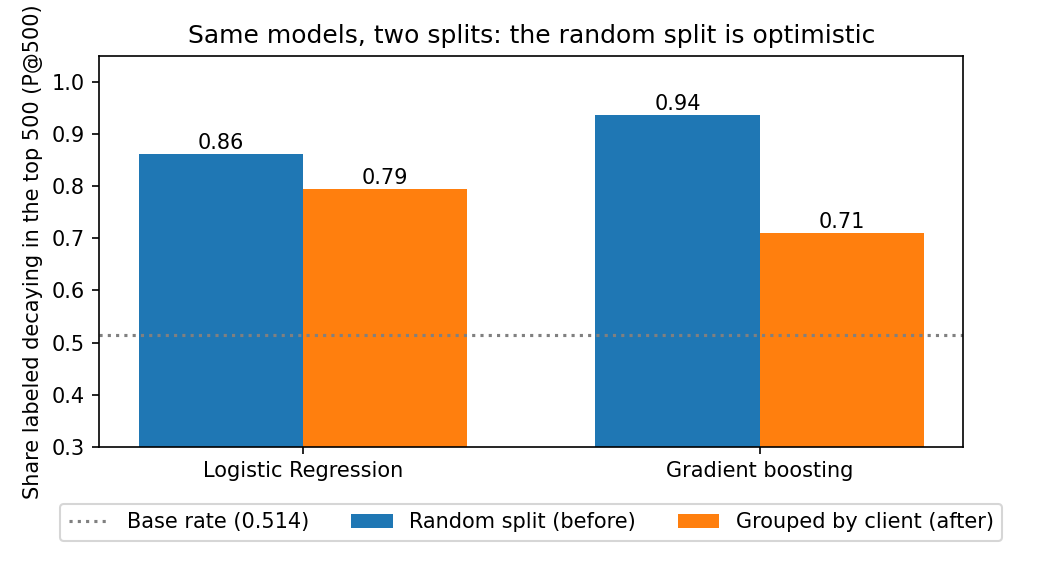

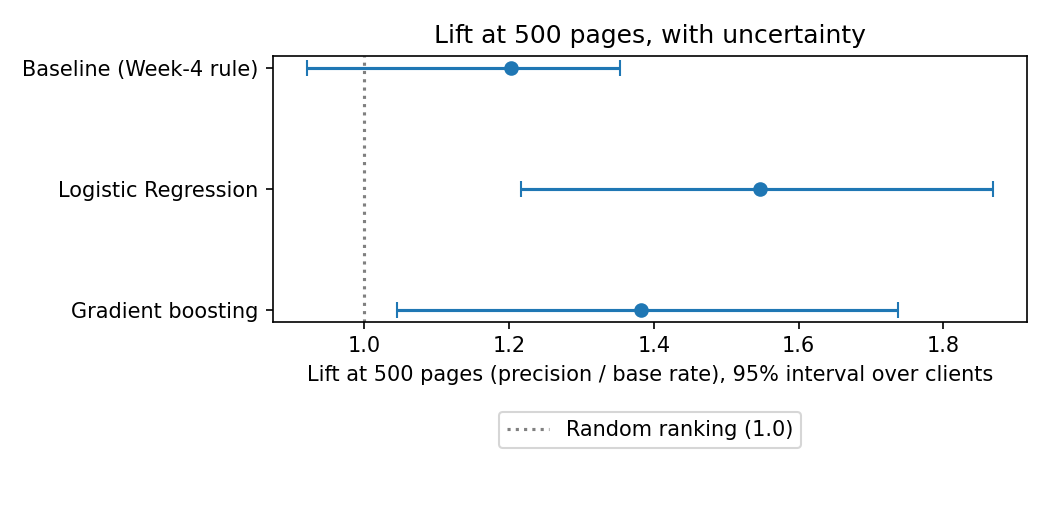

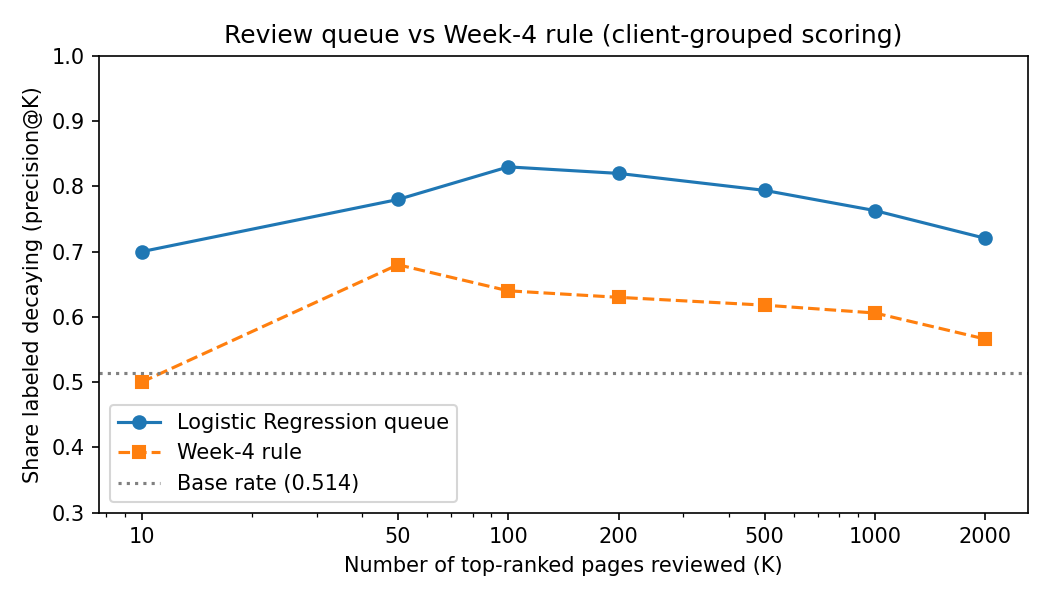

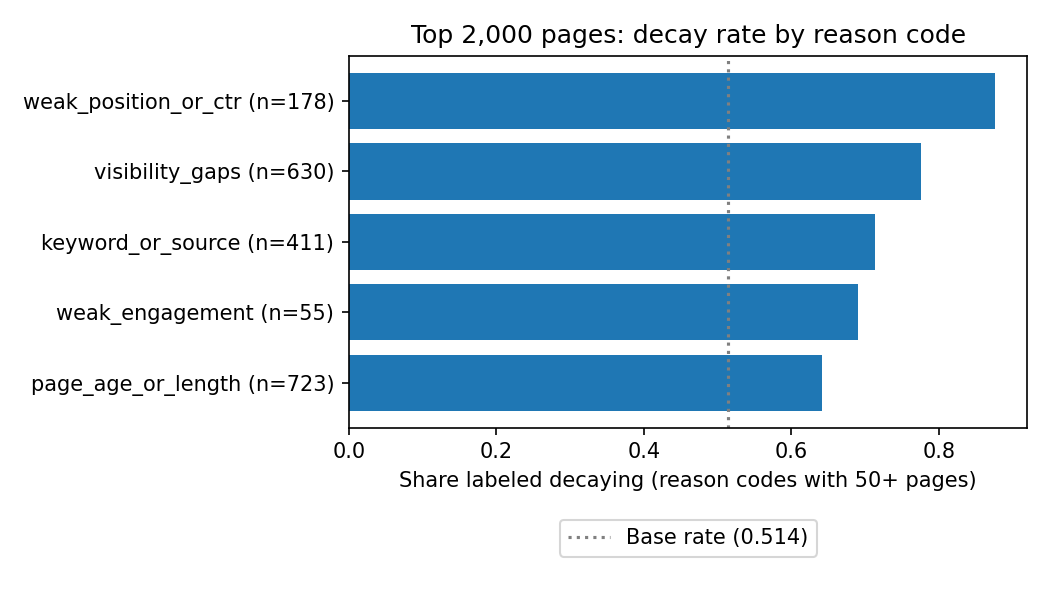

In [13]:
from IPython.display import Image, display
for name in ["before_after_split", "lift_with_intervals", "queue_precision_by_k", "decay_rate_by_reason_code"]:
    display(Image(f"work/figures/{name}.png"))

## ML-12: 5-minute demo outline

| Time | Part | What I say or show |
|---|---|---|
| 0:00–0:45 | **Question** | A content team has a few hours a week and thousands of pages. Which pages that are losing search impressions should a person look at first? |
| 0:45–1:45 | **Method** | An anonymized slice of real search data (30,000 pages; 21,758 pages from 30 clients after filtering). A page is "decaying" if its impressions fell 30% or more. I compare a hand-written rule, Logistic Regression and Gradient boosting, and I test them by holding out whole clients. |
| 1:45–3:00 | **One chart** | `before_after_split.png`. The same models under two splits. A random split says Gradient boosting finds decaying pages 94% of the time in its top 500; on clients it has never seen it is 71%. The random split lets the model recognize clients, not pages. |
| 3:00–4:00 | **One honest result** | Logistic Regression's top 500 pages were decaying close to 80% of the time, against 51% for random picks (1.55x lift, 95% interval 1.22 to 1.87). But Gradient boosting's edge over the rule cannot be told apart from zero, and without the 90-day activity numbers most of the skill disappears. So it is a screening list, not a forecast. |
| 4:00–4:45 | **One recommendation** | Use the queue as a screening list, verify the decline before acting, start from "leave it alone" for older page-one pages, and check value first, because the top 500 hold only 0.4% of the click-equivalent value. |
| 4:45–5:00 | **Close** | Next: test the same ranking on a true past-to-future label. |

## ML-12: two shareable cuts

**Social post (methodology)**

I built a model to answer one editorial question: which content pages should a human review first for lost search visibility?

First result: 94% of my gradient boosting model's top 500 pages were decaying under a random split. Then I tested it properly, on clients it had never seen: 71%. The gap was the model recognizing clients, not pages.

Two more checks changed how I read the rest. Most of the measured skill came from 90-day numbers that overlap the label window, and precision moved by 0.11 to 0.21 depending on how I picked the pages.

What I kept: a simple, readable model (about 1.5x better than random at the top of the list, with the uncertainty shown), a reason code for every page, and a list of what should never be automated.

The honest number is usually the smaller one.

Built on the FlyRank ML Internship dataset. #datascience #seo #machinelearning

**Employer-facing summary (3 sentences)**

I built a review queue that ranks content pages by how likely they are to have lost 30% or more of their search impressions, with reason codes and human-review actions, using logistic regression and gradient boosting. It ran on an anonymized slice of real production search data (21,758 pages from 30 clients after filtering) and was validated by holding out whole clients. On unseen clients its top 500 pages were decaying close to 80% of the time against 51% for random picks (1.55x lift, 95% interval 1.22 to 1.87), and I showed that a random split inflated a comparable result to 94%, so I presented it as decision support and not as a forecast.

## Self-check

Before you submit, confirm each line honestly:

- [✅] Every section above is filled — markdown thinking AND the code that backs it
- [✅] The notebook runs top to bottom with no errors (Runtime → Run all)
- [✅] No client names, URLs, or private queries anywhere
- [✅] My claims use careful words: observed, measured, directional, decision-support
- [✅] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [✅] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [✅] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
